# Notebook 15b: Zelfde tijd gisteren (persistence) carport
---
- De simpelste voorspelling: het verbruik of de opwek van de **carport** morgen is gelijk aan dat van **hetzelfde tijdstip gisteren**
- Code volgt notebook 15 (huis); alleen de locatie en de bestandsnamen verschillen
- Voor dag 2 en 3 van de forecast wordt de laatst bekende dag herhaald (er is nog geen nieuwe data)
- Wordt als eigen "model" opgeslagen in `models/results/`, zodat hij als referentiepunt in de vergelijkingsgrafieken staat
- Zelfde testvensters als LightGBM, N-HiTS/PatchTST, TimesFM en GRU/LSTM (laatste 15%, elk uur een forecast)

### 1. Waarom deze baseline?
---
- Een model is pas nuttig als het beter is dan een voorspelling die geen enkele moeite kost (Hyndman & Athanasopoulos, 2021)
- Bij energiedata met een sterk dagpatroon is *seasonal naive* (zelfde tijd vorige periode) een sterke en veelgebruikte referentie
- In notebook 14b is de relatieve MAE van dit model per definitie 1

**Bron**
- Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and Practice* (3rd ed.), hoofdstuk 5.2 "Some simple forecasting methods". OTexts. https://otexts.com/fpp3/

### 2. Inladen
---

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

#Projectmap zoeken, werkt vanuit elke submap van models/
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "prepared_data").exists())
DATA_FILE = ROOT / "prepared_data" / "forecast_targets_with_weather.parquet"
RESULTS_DIR = ROOT / "models" / "results"
MODEL_DIR = ROOT / "models" / "saved_models"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(DATA_FILE)

### 3. Instellingen
---
- Test begint bij 85% van de data, net als bij de andere 5-minutenmodellen (70/15/15 en 60/25/15 eindigen allebei op 85%)

In [2]:
stap_per_dag = 24 * 12
aantal_dagen_input = 7
input_len = aantal_dagen_input * stap_per_dag
aantal_dagen_forecast = 3
horizon = aantal_dagen_forecast * stap_per_dag
stride_test = 12

TEST_START = 0.85
LOCATIE = "carport"
TARGETS = {"consumption": "15b_Persistence_carport_cons", "generation": "15b_Persistence_carport_gen"}
MODEL_NAAM = "Zelfde tijd gisteren"

### 4. Voorspellen en scoren
---
- Zelfde filter als de andere notebooks, zodat de testvensters identiek zijn
- Trainingstijd = 0, er wordt niets geleerd
- Modelgrootte = de laatst bekende dag (288 waarden), meer heeft deze methode niet nodig

In [3]:
def scores(pred, echt):
    fout = pred - echt
    res = {"MAE": np.abs(fout).mean(), "RMSE": np.sqrt((fout ** 2).mean())}
    for d in range(aantal_dagen_forecast):
        s = slice(d * stap_per_dag, (d + 1) * stap_per_dag)
        res[f"MAE dag {d+1}"] = np.abs(fout[:, s]).mean()
    #Rolling validation: elke dag een nieuwe forecast
    dagelijks = slice(None, None, stap_per_dag // stride_test)
    res["rolling MAE"] = np.abs(fout[dagelijks]).mean(axis=1).mean()
    res["rolling RMSE"] = np.sqrt((fout[dagelijks] ** 2).mean(axis=1)).mean()
    return res


def evalueer(target, notebook):
    data = df[(df["location"] == LOCATIE) & (df["target_type"] == target)]
    data = data.dropna(subset=["pow_imputed", "Windrichting", "WindSnelheid", "LuchtVochtigheid"])
    data = data.sort_values("timestamp").reset_index(drop=True)

    y_arr = data["pow_imputed"].to_numpy()
    n = len(y_arr)
    i_val = int(n * TEST_START)
    test_origins = i_val + input_len + np.arange(0, (n - i_val) - input_len - horizon + 1, stride_test)

    h = np.arange(horizon)
    t = test_origins[:, None] + h[None, :]
    echt = y_arr[t]

    t0 = time.perf_counter()
    pred = y_arr[t - stap_per_dag * (h // stap_per_dag + 1)]
    voorspeltijd = time.perf_counter() - t0
    week = y_arr[t - input_len]

    resultaten = pd.DataFrame({MODEL_NAAM: scores(pred, echt),
                               "Persistence dag": scores(pred, echt),
                               "Persistence week": scores(week, echt)}).T
    resultaten.loc[MODEL_NAAM, "trainingstijd (s)"] = 0.0
    resultaten = resultaten.round(1)
    resultaten.loc[MODEL_NAAM, "voorspeltijd (s)"] = round(voorspeltijd, 4)

    #Het "model" is alleen de laatst bekende dag
    pad = MODEL_DIR / f"{notebook.lower()}.npy"
    np.save(pad, y_arr[test_origins[-1] - stap_per_dag:test_origins[-1]])
    resultaten.loc[MODEL_NAAM, "modelgrootte (MB)"] = round(pad.stat().st_size / 1e6, 4)

    KOLOMMEN = ["notebook", "locatie", "target", "resolutie", "testperiode", "MAE", "RMSE", "MAE dag 1", "MAE dag 2",
                "MAE dag 3", "rolling MAE", "rolling RMSE", "trainingstijd (s)", "voorspeltijd (s)",
                "modelgrootte (MB)"]
    tijden = pd.to_datetime(data["timestamp"])
    resultaten["notebook"] = notebook
    resultaten["locatie"] = LOCATIE
    resultaten["target"] = target
    resultaten["resolutie"] = "5 min"
    resultaten["testperiode"] = f"{tijden.iloc[i_val]:%Y-%m-%d} t/m {tijden.iloc[-1]:%Y-%m-%d}"
    resultaten = resultaten.reindex(columns=KOLOMMEN)
    resultaten.to_csv(RESULTS_DIR / f"{notebook.lower()}.csv")
    return resultaten, y_arr, test_origins, pred


uitkomsten = {}
for target, notebook in TARGETS.items():
    resultaten, y_arr, test_origins, pred = evalueer(target, notebook)
    uitkomsten[target] = (y_arr, test_origins, pred)
    print(f"\n{target.upper()} ({len(test_origins)} forecasts)")
    display(resultaten)


CONSUMPTION (2443 forecasts)


,notebook,locatie,target,resolutie,testperiode,MAE,RMSE,MAE dag 1,MAE dag 2,MAE dag 3,rolling MAE,rolling RMSE,trainingstijd (s),voorspeltijd (s),modelgrootte (MB)
Zelfde tijd gisteren,15b_Persistence_carport_cons,carport,consumption,5 min,2026-01-07 t/m 2026-09-02,2404.9,4378.0,2370.9,2382.4,2461.4,2410.2,4217.7,0.0,0.0107,0.0024
Persistence dag,15b_Persistence_carport_cons,carport,consumption,5 min,2026-01-07 t/m 2026-09-02,2404.9,4378.0,2370.9,2382.4,2461.4,2410.2,4217.7,NaN,NaN,NaN
Persistence week,15b_Persistence_carport_cons,carport,consumption,5 min,2026-01-07 t/m 2026-09-02,2345.3,4267.6,2347.9,2351.1,2336.9,2348.1,4188.7,NaN,NaN,NaN



GENERATION (2406 forecasts)


,notebook,locatie,target,resolutie,testperiode,MAE,RMSE,MAE dag 1,MAE dag 2,MAE dag 3,rolling MAE,rolling RMSE,trainingstijd (s),voorspeltijd (s),modelgrootte (MB)
Zelfde tijd gisteren,15b_Persistence_carport_gen,carport,generation,5 min,2026-01-08 t/m 2026-09-02,3326.0,7443.0,2943.1,3376.6,3658.3,3327.2,6509.8,0.0,0.0101,0.0024
Persistence dag,15b_Persistence_carport_gen,carport,generation,5 min,2026-01-08 t/m 2026-09-02,3326.0,7443.0,2943.1,3376.6,3658.3,3327.2,6509.8,NaN,NaN,NaN
Persistence week,15b_Persistence_carport_gen,carport,generation,5 min,2026-01-08 t/m 2026-09-02,4642.2,9859.8,4591.3,4658.7,4676.6,4638.6,8425.9,NaN,NaN,NaN


### 5. Voorbeeld
---
- Eén forecast per target: grijs is de historie, de voorspelling is een kopie van de laatste dag

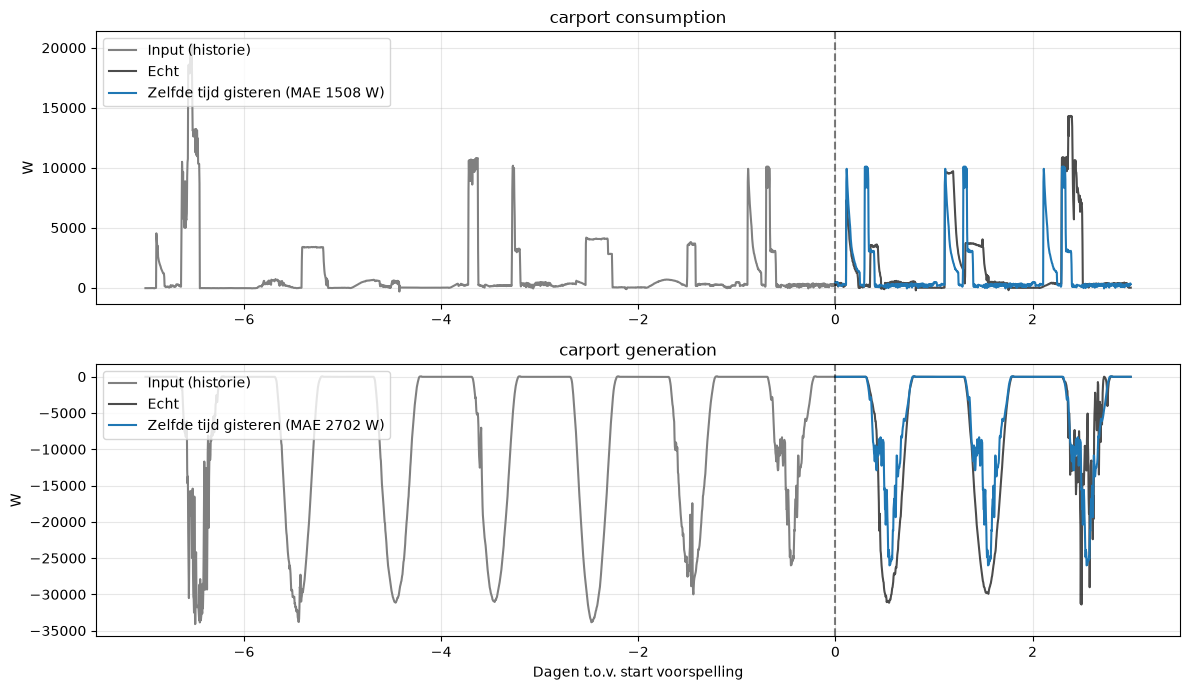

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
for ax, (target, (y_arr, test_origins, pred)) in zip(axes, uitkomsten.items()):
    idx = len(test_origins) // 2
    o = test_origins[idx]
    t_hist = np.arange(-input_len, 0) / stap_per_dag
    t_fc = np.arange(horizon) / stap_per_dag
    mae = np.abs(pred[idx] - y_arr[o:o + horizon]).mean()
    ax.plot(t_hist, y_arr[o - input_len:o], color="grey", label="Input (historie)")
    ax.plot(t_fc, y_arr[o:o + horizon], color="black", alpha=0.7, label="Echt")
    ax.plot(t_fc, pred[idx], label=f"Zelfde tijd gisteren (MAE {mae:.0f} W)")
    ax.axvline(0, color="black", linestyle="--", alpha=0.5)
    ax.set_title(f"{LOCATIE} {target}")
    ax.set_ylabel("W")
    ax.grid(alpha=0.3)
    ax.legend(loc="upper left")
axes[-1].set_xlabel("Dagen t.o.v. start voorspelling")
plt.tight_layout()
plt.show()